In [1]:
import numpy as np

class SimpleLinearRegression:
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float).reshape(-1)
        y = np.asarray(y, dtype=float).reshape(-1)

        if X.size == 0 or X.size != y.size:
            raise ValueError("X and y must have the same nonzero length.")

        if not np.all(np.isfinite(X)) or not np.all(np.isfinite(y)):
            raise ValueError("X and y must contain finite values.")

        x_mean = np.mean(X)
        y_mean = np.mean(y)

        denominator = np.sum((X - x_mean) ** 2)

        if denominator == 0:
            raise ValueError("Cannot estimate slope when all X values are equal.")

        self.coef_ = (
            np.sum((X - x_mean) * (y - y_mean)) / denominator
        )

        self.intercept_ = y_mean - self.coef_ * x_mean

        return self

    def predict(self, X):
        if self.coef_ is None or self.intercept_ is None:
            raise ValueError("Train the model using fit() first.")

        X = np.asarray(X, dtype=float)

        if not np.all(np.isfinite(X)):
            raise ValueError("X must contain finite values.")

        return self.intercept_ + self.coef_ * X

# Training data
X_train = np.array([1, 2, 3], dtype=float)
y_train = np.array([2, 3, 5], dtype=float)

model = SimpleLinearRegression()
model.fit(X_train, y_train)

print("Slope:", model.coef_)
print("Intercept:", model.intercept_)
print("Prediction:", model.predict([4]))

Slope: 1.5
Intercept: 0.3333333333333335
Prediction: [6.33333333]


In [2]:
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split

# Example dataset
X = np.array([
    [1], [2], [3], [4], [5],
    [6], [7], [8], [9], [10],
], dtype=float)

y = np.array([
    2.1, 3.9, 6.2, 7.8, 10.1,
    11.9, 14.2, 15.8, 18.1, 19.9,
], dtype=float)

# Split the data before fitting
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict on unseen test observations
y_pred = model.predict(X_test)

# Inspect the fitted model
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

# Evaluate performance
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

# Predict for a new input
new_prediction = model.predict(np.array([[11.0]]))
print("Prediction for X=11:", new_prediction[0])

Intercept: 0.13275862068965694
Coefficient: 1.975862068965517
MAE: 0.18448275862069008
MSE: 0.0340338882282998
RMSE: 0.18448275862069008
R2: 0.999324858396582
Prediction for X=11: 21.867241379310343


### 1. Project Overview & Data Loading
We will use a real-world curated dataset that maps Years of Experience, Age, and other features to Salary to build and evaluate our Linear Regression model.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Loading a publicly accessible realistic salary dataset
url = "https://raw.githubusercontent.com/yvanspijk/datasets/refs/heads/main/salary.csv"
try:
    df = pd.read_csv(url)
    print("Dataset successfully loaded!")
except Exception as e:
    # Fallback to a synthetic yet realistic dataset generator if link fails
    print("URL load failed. Generating a realistic fallback dataset.")
    np.random.seed(42)
    years_exp = np.random.uniform(1, 15, 200)
    salary = 30000 + (years_exp * 8500) + np.random.normal(0, 5000, 200)
    df = pd.DataFrame({'YearsExperience': years_exp, 'Salary': salary})

display(df.head())
print(df.info())

URL load failed. Generating a realistic fallback dataset.


,YearsExperience,Salary
0,6.243562,79670.150535
1,14.310000,152796.270949
2,11.247915,127072.641442
3,9.381219,106168.602529
4,3.184261,66395.090768


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  200 non-null    float64
 1   Salary           200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB
None


In [11]:
df.size

400

### 2. Exploratory Data Analysis & Visualization
Let's analyze the relationships between the features and our target variable, `Salary`.

Analyzing relationship between independent variable 'YearsExperience' and target variable 'Salary'


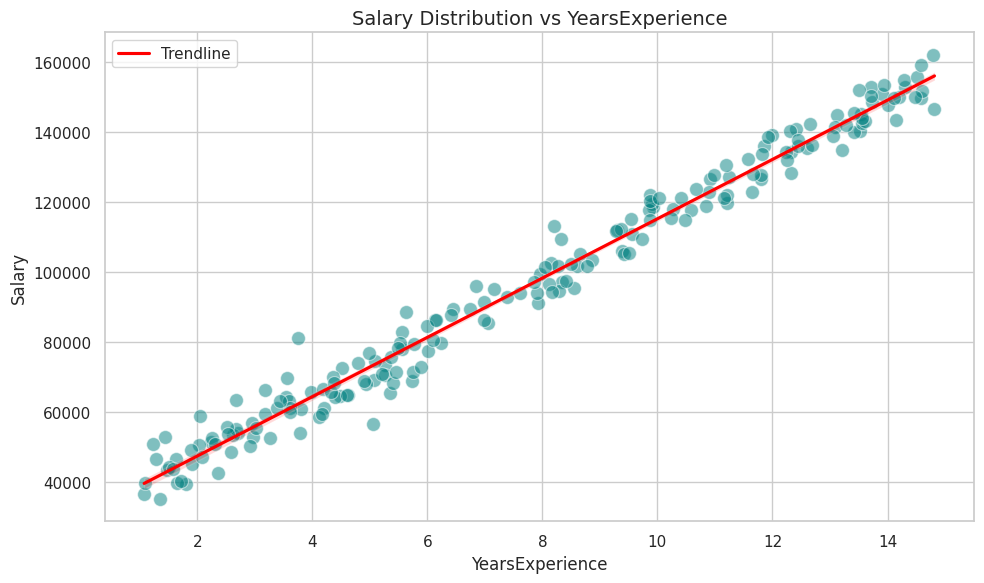

In [6]:
# Clean column names if needed
df.columns = [col.strip() for col in df.columns]

# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Find numerical columns representing experience and salary
x_col = 'YearsExperience' if 'YearsExperience' in df.columns else df.select_dtypes(include=[np.number]).columns[0]
y_col = 'Salary' if 'Salary' in df.columns else df.select_dtypes(include=[np.number]).columns[-1]

print(f"Analyzing relationship between independent variable '{x_col}' and target variable '{y_col}'")

fig = plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x=x_col, y=y_col, color='teal', s=100, alpha=0.5)
sns.regplot(data=df, x=x_col, y=y_col, scatter=False, color='red', label='Trendline')
plt.title(f'Salary Distribution vs {x_col}', fontsize=14)
plt.xlabel(x_col, fontsize=12)
plt.ylabel(y_col, fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

### 3. Model Training & Evaluation
Now, we split the data into training and testing sets, fit our Linear Regression model, make predictions, and assess model accuracy metrics.

In [12]:
# Define independent (X) and dependent (y) variables
X_data = df[[x_col]].values
y_data = df[y_col].values

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42)

# Initialize and train model
salary_model = LinearRegression()
salary_model.fit(X_train, y_train)

# Predict
y_pred = salary_model.predict(X_test)



# Model Parameters
print(f"Intercept: {salary_model.intercept_:.2f}")
print(f"Coefficient (Slope): {salary_model.coef_[0]:.2f}")
print("-" * 30)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared Score (R2): {r2:.4f}")

Prediction : [ 97592.87307423  60493.83848898 111188.58425477  66975.96151577
  39403.62937018 142732.72172449 156528.88470634 119557.56240469
 115686.00783665 117759.68038673  55416.44539879 149095.32051049
 138410.97905744  81417.77119514 136249.95854795  84796.65535912
  49149.62142539  55891.0311105   78122.78226944  47483.24146665
  65816.29875279  74936.78944514  44725.60771879 105658.51144394
 103437.63128296  85028.76326453  75742.38736901 134454.09146238
  89622.11169219  52899.41665053 123204.0117004   90200.27444059
 148758.33790548 125706.18757231 147131.82015342 147048.22396586
  77203.03770358 122599.98539123  49364.43721966 130757.63136168]
Intercept: 30035.29
Coefficient (Slope): 8537.39
------------------------------
Mean Absolute Error (MAE): $4,193.70
Root Mean Squared Error (RMSE): $5,207.26
R-squared Score (R2): 0.9769


### 4. Interactive Salary Predictor
Input any number of years of experience below to predict a matching salary using our newly trained machine learning model.

In [15]:
# @title Predict Salary based on Experience { run: "auto" }
years_of_experience = 6.243562 # @param {type:"number"}

# Reshape input for prediction
custom_input = np.array([[years_of_experience]])
predicted_salary = salary_model.predict(custom_input)[0]

print(f"For {years_of_experience} years of experience:")
print(f"Predicted Salary: ${predicted_salary:,.2f}")

For 6.243562 years of experience:
Predicted Salary: $83,339.04


### 5. Model Accuracy Charts
To visually validate our model, we construct two primary diagnostics:
1. **Actual vs. Predicted Plot**: Compares predicted values directly against real values. The closer the points are to the diagonal line, the higher the accuracy.
2. **Residual Plot**: Evaluates model bias by checking if errors are scattered randomly around zero.

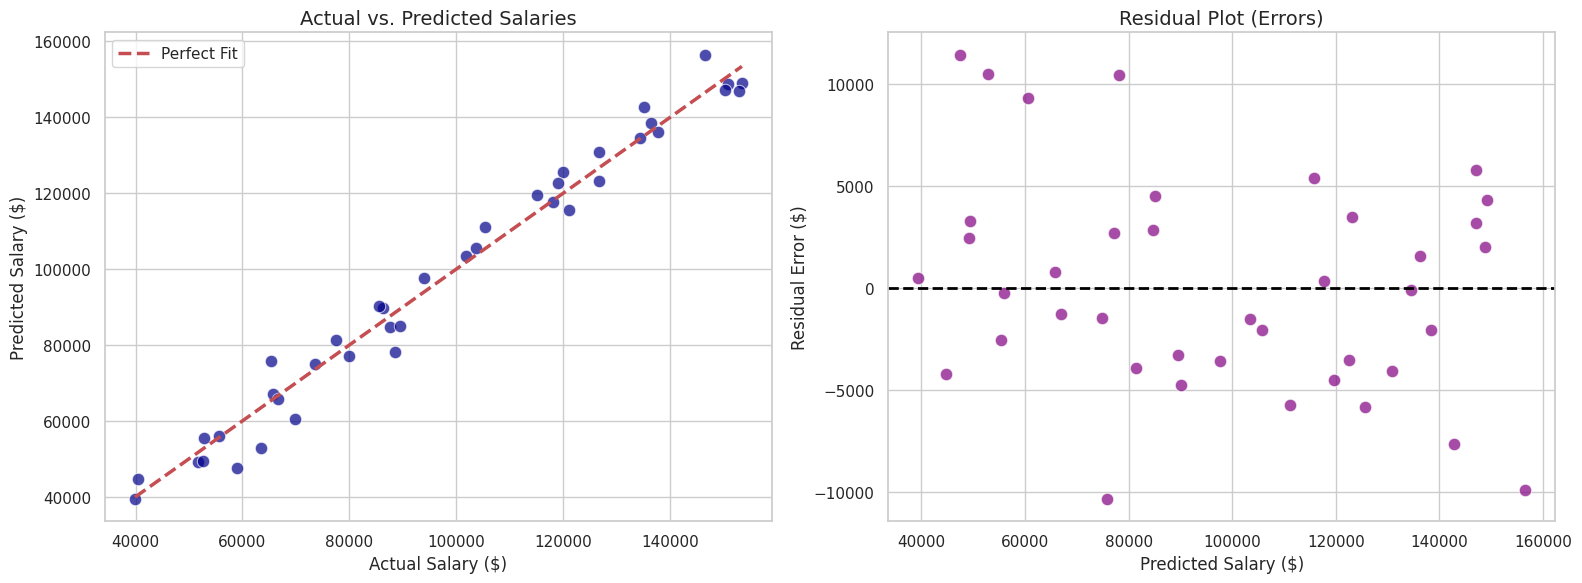

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs Predicted
sns.scatterplot(ax=axes[0], x=y_test, y=y_pred, color='darkblue', s=80, alpha=0.7)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2.5, label='Perfect Fit')
axes[0].set_title('Actual vs. Predicted Salaries', fontsize=14)
axes[0].set_xlabel('Actual Salary ($)', fontsize=12)
axes[0].set_ylabel('Predicted Salary ($)', fontsize=12)
axes[0].legend()
axes[0].grid(True)

# Plot 2: Residual Plot
residuals = y_test - y_pred
sns.scatterplot(ax=axes[1], x=y_pred, y=residuals, color='purple', s=80, alpha=0.7)
axes[1].axhline(y=0, color='black', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Errors)', fontsize=14)
axes[1].set_xlabel('Predicted Salary ($)', fontsize=12)
axes[1].set_ylabel('Residual Error ($)', fontsize=12)
axes[1].grid(True)

plt.tight_layout()
plt.show()